# Model 3 — 07 Error Analysis & Drift Diagnostics

## Diagnostic quality gate
Analyze the Friday-DDoS generalization failure. This notebook is diagnostic only and never overwrites the production model.

In [4]:
from pathlib import Path
import pandas as pd
import joblib

# ---------------------------------------------------------
# Locate EVIDENT project root
# ---------------------------------------------------------
cwd = Path.cwd()

PROJECT_ROOT = None

for p in [cwd, *cwd.parents]:
    if (p / "models" / "behavior" / "production").exists():
        PROJECT_ROOT = p
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate EVIDENT project root. "
        "Make sure the notebook is opened inside the EVIDENT project."
    )

print("Project root:", PROJECT_ROOT)

# ---------------------------------------------------------
# Production model
# ---------------------------------------------------------
PROD_DIR = PROJECT_ROOT / "models" / "behavior" / "production"

MODEL_PATH = PROD_DIR / "network_threat_model.pkl"

if not MODEL_PATH.exists():
    raise FileNotFoundError(
        f"Production model not found:\n{MODEL_PATH}"
    )

artifact = joblib.load(MODEL_PATH)

model = artifact["binary_model"]
features = artifact["feature_columns"]

print("Model loaded:", MODEL_PATH)
print("Expected features:", len(features))

# ---------------------------------------------------------
# Locate CIC-IDS2017 Friday DDoS file
# ---------------------------------------------------------
TARGET_FILE = "Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv"

candidate_dirs = [
    PROJECT_ROOT / "data" / "raw" / "behavior",
    PROJECT_ROOT / "data" / "raw" / "behaviour",
    PROJECT_ROOT / "data" / "raw",
]

path = None

# First check expected locations
for directory in candidate_dirs:
    candidate = directory / TARGET_FILE

    if candidate.exists():
        path = candidate
        break

# If not found, search the entire project
if path is None:
    print("File not found in expected locations.")
    print("Searching EVIDENT project...")

    matches = list(PROJECT_ROOT.rglob(TARGET_FILE))

    if matches:
        path = matches[0]

# Final validation
if path is None:
    raise FileNotFoundError(
        f"\nCould not find:\n{TARGET_FILE}\n\n"
        f"Searched under:\n{PROJECT_ROOT}\n\n"
        "Download/copy the CIC-IDS2017 CSV into "
        "data/raw/behavior/ and run this cell again."
    )

print("Dataset found:", path)

# ---------------------------------------------------------
# Load dataset
# ---------------------------------------------------------
df = pd.read_csv(path, low_memory=False)

df.columns = [
    str(c).strip().replace("\ufeff", "")
    for c in df.columns
]

print("Dataset shape:", df.shape)

# ---------------------------------------------------------
# Validate label
# ---------------------------------------------------------
if "Label" not in df.columns:
    raise ValueError(
        f"'Label' column not found.\nColumns available:\n{list(df.columns)}"
    )

y = (
    df["Label"]
    .astype(str)
    .str.strip()
    .str.upper()
    .str.replace(" ", "_", regex=False)
    != "BENIGN"
).astype(int)

X = df.reindex(columns=features).copy()

print("X shape:", X.shape)
print("Attack rate:", y.mean())
print("\nOriginal labels:")
print(df["Label"].value_counts().head(20))

Project root: c:\Users\bimal\OneDrive\Desktop\EVIDENT
Model loaded: c:\Users\bimal\OneDrive\Desktop\EVIDENT\models\behavior\production\network_threat_model.pkl
Expected features: 67
Dataset found: c:\Users\bimal\OneDrive\Desktop\EVIDENT\data\raw\behaviour\Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Dataset shape: (225745, 79)
X shape: (225745, 67)
Attack rate: 0.5671310549513832

Original labels:
Label
DDoS      128027
BENIGN     97718
Name: count, dtype: int64


In [5]:

a=df[["Label"]].copy()
a["probability"]=prob
a["prediction"]=np.where(pred==1,"ATTACK","BENIGN")
a["error"]=np.where(pred==y,"CORRECT",np.where(pred==1,"FALSE_POSITIVE","FALSE_NEGATIVE"))
print(a["error"].value_counts())
print("\nFalse negatives:")
print(a[a.error=="FALSE_NEGATIVE"]["probability"].describe())
print("\nFalse positives:")
print(a[a.error=="FALSE_POSITIVE"]["probability"].describe())
a.to_csv(META_DIR/"friday_ddos_error_analysis.csv",index=False)


error
CORRECT           225322
FALSE_POSITIVE       377
FALSE_NEGATIVE        46
Name: count, dtype: int64

False negatives:
count    46.000000
mean      0.121974
std       0.176366
min       0.000004
25%       0.000953
50%       0.002908
75%       0.313202
max       0.483165
Name: probability, dtype: float64

False positives:
count    377.000000
mean       0.765886
std        0.139794
min        0.500717
25%        0.671229
50%        0.751297
75%        0.885423
max        0.999808
Name: probability, dtype: float64


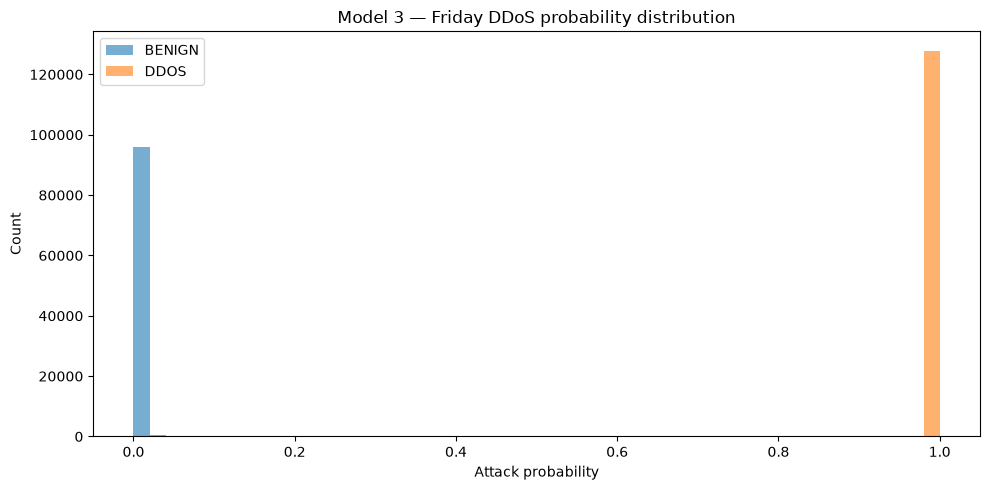

In [6]:

plt.figure(figsize=(10,5))
plt.hist(prob[y==0],bins=50,alpha=.6,label="BENIGN")
plt.hist(prob[y==1],bins=50,alpha=.6,label="DDOS")
plt.xlabel("Attack probability"); plt.ylabel("Count")
plt.title("Model 3 — Friday DDoS probability distribution")
plt.legend(); plt.tight_layout(); plt.show()
